# Question-Driven EDA : Ames Housing Data

[Contents]  
- 다양한 시각화와 통계 정보를 활용하여 데이터의 특성을 이해하고, 전처리가 필요한 문제점을 직접 발견하는 것이 목표
- 각 단계에서 얻은 결과를 바탕으로 왜 이러한 현상이 나타나는지, 어떤 전처리가 필요할지 스스로 판단해 보는 것이 이번 실습의 방향성  
- EDA 결과를 정답처럼 받아들이기보다, 관찰한 근거를 바탕으로 질문에 답하는 것 권장  
  
[Data]  
Ames Housing Raw 데이터를 바탕으로 교육용으로 간소화
- Target: SalePrice
- Numeric Features: 10개
- Categorical Features: 4개

[Note]  
- 배포된 "ames_housing_edu.csv" 파일을 직접 업로드


## 1. 라이브러리 Import

- 데이터 처리: pandas, numpy
- 시각화: matplotlib, seaborn


In [2]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas version:", pd.__version__)

pandas version: 3.0.3


## 2. Config

- 실수값을 소수 둘째 자리까지 출력


In [3]:
pd.set_option("display.float_format", "{:.2f}".format)

## 3. 데이터 업로드

- 배포된 "ames_housing_edu.csv" 파일을 업로드
- 업로드한 파일을 DataFrame으로 로드


In [5]:
'''
from google.colab import files

uploaded = files.upload()

csv_filename = "ames_housing_edu.csv"
if csv_filename not in uploaded:
    raise FileNotFoundError(
        f"{csv_filename} 파일을 업로드 하세요. "
        f"업로드된 파일: {list(uploaded.keys())}"
    )
'''
df = pd.read_csv("ames_housing_edu.csv", encoding = 'utf-8-sig')

print("Uploaded data shape:", df.shape)
display(df.head())

Uploaded data shape: (2930, 15)


,SalePrice,Overall_Qual,Overall_Cond,Gr_Liv_Area,Lot_Area,Year_Built,Total_Bsmt_SF,Garage_Cars,Garage_Yr_Blt,Full_Bath,Bedroom_AbvGr,Neighborhood,House_Style,Kitchen_Qual,Exter_Qual
0,215000,6,5,1656,31770,1960,1080.00,2.00,1960.00,1,3,NAmes,1Story,TA,TA
1,105000,5,6,896,11622,1961,882.00,1.00,1961.00,1,2,NAmes,1Story,TA,TA
2,172000,6,6,1329,14267,1958,1329.00,1.00,1958.00,1,3,NAmes,1Story,Gd,TA
3,244000,7,5,2110,11160,1968,2110.00,2.00,1968.00,2,3,NAmes,1Story,Ex,Gd
4,189900,5,5,1629,13830,1997,928.00,2.00,1997.00,2,3,Gilbert,2Story,TA,TA


## 4. 데이터 구조 확인

[Question 1]  
- 데이터는 몇 개의 행과 열로 구성되어 있는가?
- Target 변수는 무엇인가?
- 수치형 변수와 범주형 변수는 각각 몇 개인가?
- 분석 전에 자료형을 변경해야 할 변수는 보이는가?


In [6]:
print("Data shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nData samples:")
display(df.head())


Data shape: (2930, 15)

Column names:
['SalePrice', 'Overall_Qual', 'Overall_Cond', 'Gr_Liv_Area', 'Lot_Area', 'Year_Built', 'Total_Bsmt_SF', 'Garage_Cars', 'Garage_Yr_Blt', 'Full_Bath', 'Bedroom_AbvGr', 'Neighborhood', 'House_Style', 'Kitchen_Qual', 'Exter_Qual']

Data types:


,dtype
SalePrice,int64
Overall_Qual,int64
Overall_Cond,int64
Gr_Liv_Area,int64
Lot_Area,int64
Year_Built,int64
Total_Bsmt_SF,float64
Garage_Cars,float64
Garage_Yr_Blt,float64
Full_Bath,int64



Data samples:


,SalePrice,Overall_Qual,Overall_Cond,Gr_Liv_Area,Lot_Area,Year_Built,Total_Bsmt_SF,Garage_Cars,Garage_Yr_Blt,Full_Bath,Bedroom_AbvGr,Neighborhood,House_Style,Kitchen_Qual,Exter_Qual
0,215000,6,5,1656,31770,1960,1080.00,2.00,1960.00,1,3,NAmes,1Story,TA,TA
1,105000,5,6,896,11622,1961,882.00,1.00,1961.00,1,2,NAmes,1Story,TA,TA
2,172000,6,6,1329,14267,1958,1329.00,1.00,1958.00,1,3,NAmes,1Story,Gd,TA
3,244000,7,5,2110,11160,1968,2110.00,2.00,1968.00,2,3,NAmes,1Story,Ex,Gd
4,189900,5,5,1629,13830,1997,928.00,2.00,1997.00,2,3,Gilbert,2Story,TA,TA


In [7]:
# 수치형 변수와 범주형 변수 구분
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("Numeric variables:", len(numeric_columns), numeric_columns)
print("Categorical variables:", len(categorical_columns), categorical_columns)

Numeric variables: 11 ['SalePrice', 'Overall_Qual', 'Overall_Cond', 'Gr_Liv_Area', 'Lot_Area', 'Year_Built', 'Total_Bsmt_SF', 'Garage_Cars', 'Garage_Yr_Blt', 'Full_Bath', 'Bedroom_AbvGr']
Categorical variables: 4 ['Neighborhood', 'House_Style', 'Kitchen_Qual', 'Exter_Qual']


/var/folders/8g/h9nz457x1qv8cwzh60p67dlw0000gn/T/ipykernel_57818/3576946816.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.tolist()


## 5. 기술통계 확인

[Question 2]  
- 주택가격의 평균과 중앙값은 비슷한가?
- 평균과 중앙값의 차이는 분포의 어떤 특징을 암시하는가?
- 최소값과 최대값의 차이가 큰 변수는 무엇인가?
- 변수의 단위가 서로 다르다는 점은 이후 분석에 어떤 영향을 줄 수 있는가?


In [8]:
# 수치형 변수 기술통계
display(df[numeric_columns].describe().T)

# 범주형 변수 기술통계
display(df[categorical_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
SalePrice,2930.00,180796.06,79886.69,12789.00,129500.00,160000.00,213500.00,755000.00
Overall_Qual,2930.00,6.09,1.41,1.00,5.00,6.00,7.00,10.00
Overall_Cond,2930.00,5.56,1.11,1.00,5.00,5.00,6.00,9.00
Gr_Liv_Area,2930.00,1499.69,505.51,334.00,1126.00,1442.00,1742.75,5642.00
Lot_Area,2930.00,10147.92,7880.02,1300.00,7440.25,9436.50,11555.25,215245.00
Year_Built,2930.00,1971.36,30.25,1872.00,1954.00,1973.00,2001.00,2010.00
Total_Bsmt_SF,2929.00,1051.61,440.62,0.00,793.00,990.00,1302.00,6110.00
Garage_Cars,2929.00,1.77,0.76,0.00,1.00,2.00,2.00,5.00
Garage_Yr_Blt,2771.00,1978.13,25.53,1895.00,1960.00,1979.00,2002.00,2207.00
Full_Bath,2930.00,1.57,0.55,0.00,1.00,2.00,2.00,4.00


,count,unique,top,freq
Neighborhood,2930,28,NAmes,443
House_Style,2930,8,1Story,1481
Kitchen_Qual,2930,5,TA,1494
Exter_Qual,2930,4,TA,1799


## 6. 결측치 확인

[Question 3]  
- 결측치가 있는 변수는 무엇인가?
- 결측치는 단순한 누락일까, 특정 시설이 없다는 의미일까?
- 결측치 비율이 분석에 영향을 줄 만큼 큰가?
- 결측치 처리 전에 원래 의미를 확인해야 하는 이유는 무엇인가?


In [9]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Ratio(%)": df.isna().mean() * 100
}).sort_values("Missing_Count", ascending=False)

missing_summary = missing_summary[missing_summary["Missing_Count"] > 0]
display(missing_summary)

,Missing_Count,Missing_Ratio(%)
Garage_Yr_Blt,159,5.43
Total_Bsmt_SF,1,0.03
Garage_Cars,1,0.03


## 7. Target 분포 확인

[Question 4]  
- SalePrice는 대칭적인 분포인가?
- 고가 주택이 분포의 오른쪽 꼬리를 길게 만드는가?
- 평균과 중앙값 중 대표값으로 어느 값이 더 적절해 보이는가?
- 향후 회귀분석에서 Target 변환을 고려할 필요가 있는가?


Mean   : 180796.0600682594
Median : 160000.0
Skewness: 1.7435000757376466


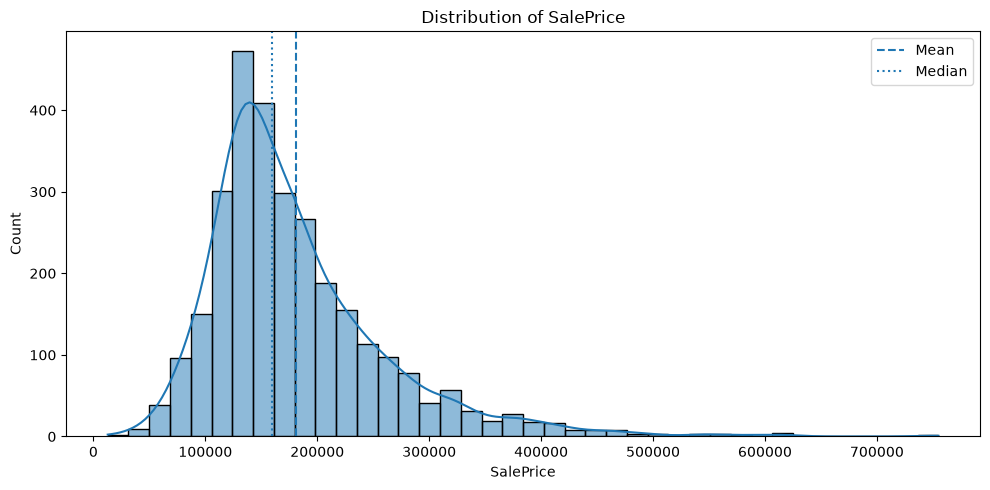

In [10]:
target = "SalePrice"

print("Mean   :", df[target].mean())
print("Median :", df[target].median())
print("Skewness:", df[target].skew())

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x=target, bins=40, kde=True)
plt.axvline(df[target].mean(), linestyle="--", label="Mean")
plt.axvline(df[target].median(), linestyle=":", label="Median")
plt.title("Distribution of SalePrice")
plt.legend()
plt.tight_layout()
plt.show()

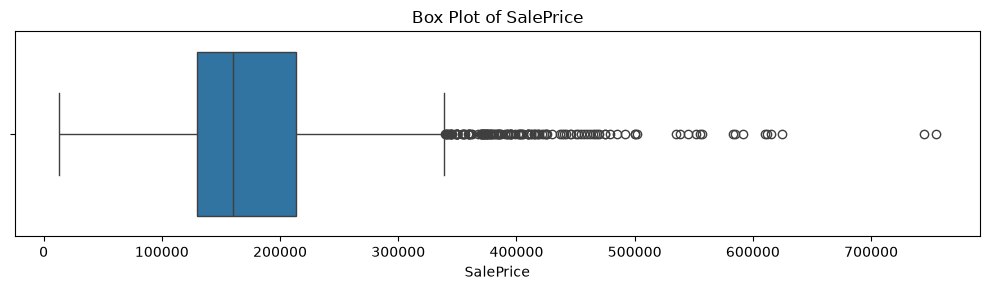

In [11]:
plt.figure(figsize=(10, 3))
sns.boxplot(data=df, x=target)
plt.title("Box Plot of SalePrice")
plt.tight_layout()
plt.show()

## 8. 수치형 변수 분포 확인

[Question 5]  
- 강한 오른쪽 왜도를 보이는 변수는 무엇인가?
- 값이 특정 구간에 집중된 변수는 무엇인가?
- 이상치 후보가 많은 변수는 무엇인가?
- 모든 수치형 변수에 동일한 전처리를 적용하는 것이 적절한가?


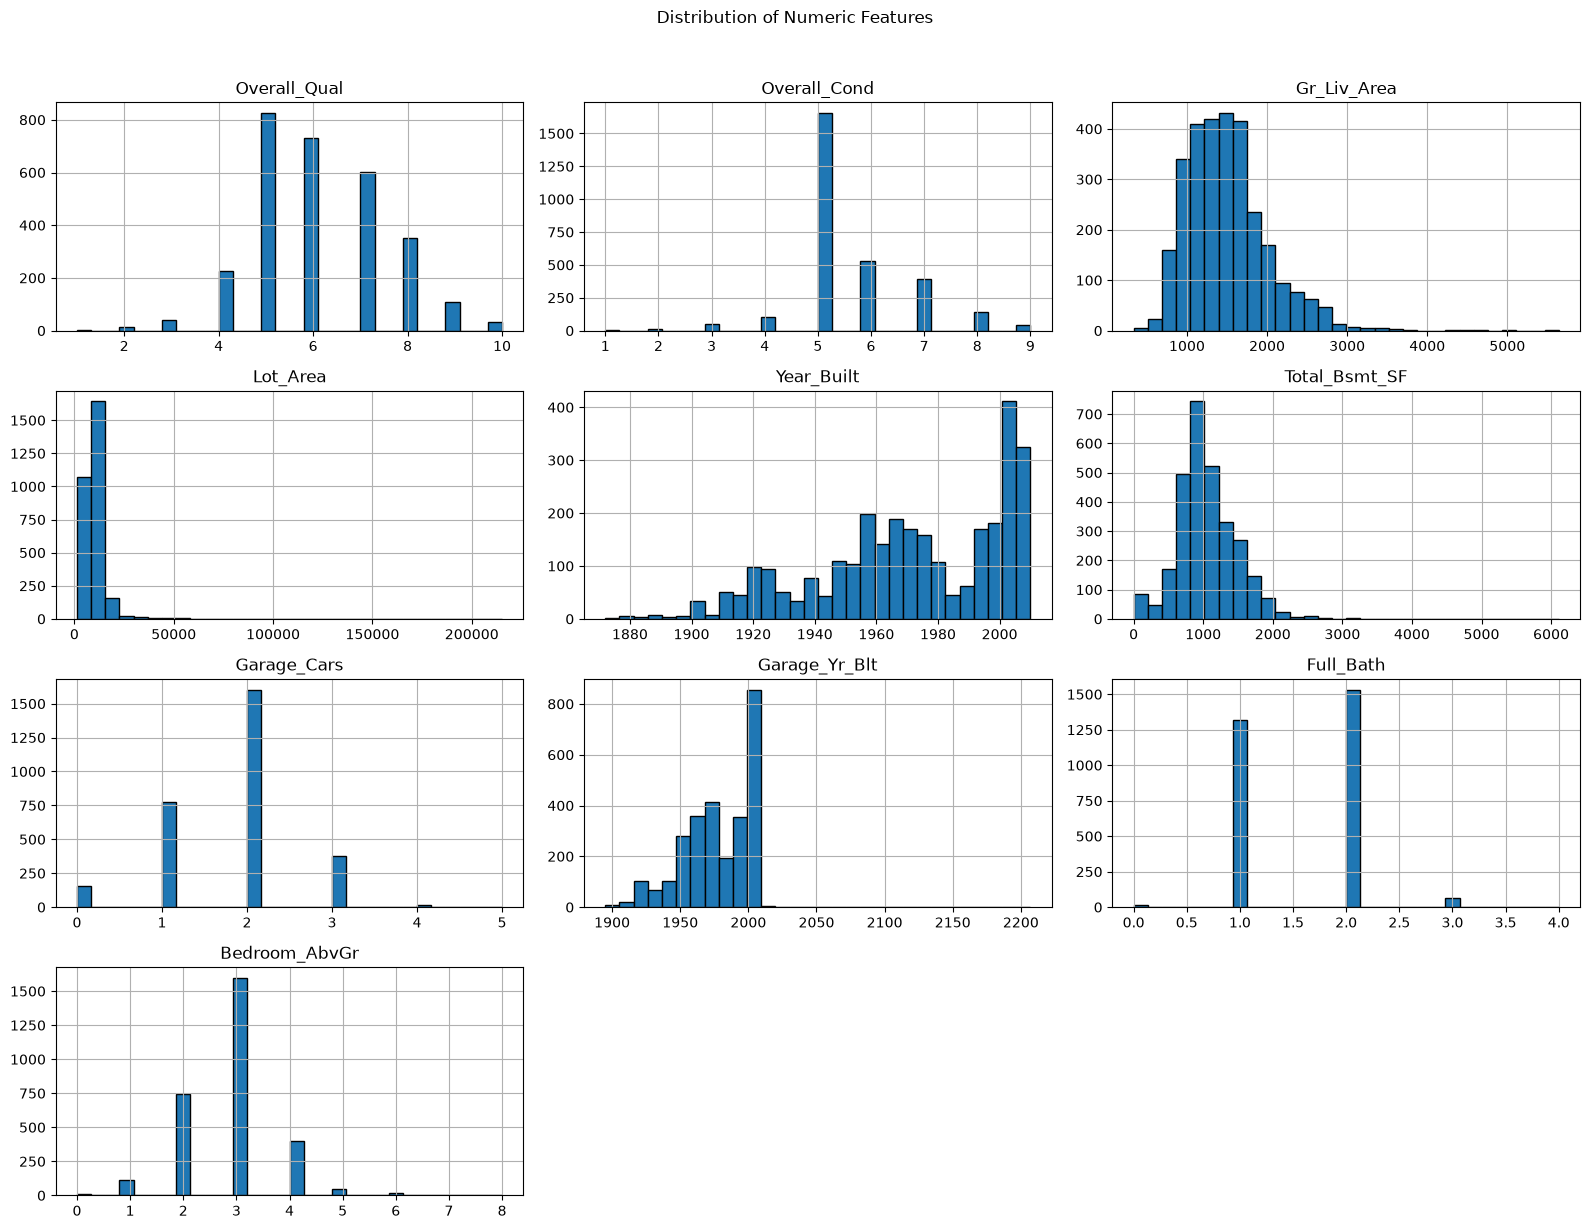

In [12]:
# 수치형 설명변수 분포
numeric_features = [column for column in numeric_columns if column != target]

df[numeric_features].hist(
    bins=30,
    figsize=(16, 12),
    edgecolor="black"
)
plt.suptitle("Distribution of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()

In [13]:
skewness = (
    df[numeric_features]
    .skew(numeric_only=True)
    .sort_values(ascending=False)
    .to_frame("Skewness")
)

display(skewness)

,Skewness
Lot_Area,12.82
Gr_Liv_Area,1.27
Total_Bsmt_SF,1.16
Overall_Cond,0.57
Bedroom_AbvGr,0.31
Overall_Qual,0.19
Full_Bath,0.17
Garage_Cars,-0.22
Garage_Yr_Blt,-0.38
Year_Built,-0.60


## 9. 이상치 후보 확인

[Question 6]  
- IQR 기준으로 이상치 후보가 많은 변수는 무엇인가?
- 통계적 이상치가 반드시 오류 데이터라고 볼 수 있는가?
- Gr_Liv_Area, Lot_Area, SalePrice의 극단값은 실제 대형 주택일 가능성이 있는가?


In [14]:
def iqr_outlier_summary(data, columns):
    results = []

    for column in columns:
        series = data[column].dropna()
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outlier_count = ((series < lower_bound) | (series > upper_bound)).sum()

        results.append({
            "Variable": column,
            "Lower_Bound": lower_bound,
            "Upper_Bound": upper_bound,
            "Outlier_Count": outlier_count,
            "Outlier_Ratio(%)": outlier_count / len(series) * 100
        })

    return pd.DataFrame(results).sort_values("Outlier_Count", ascending=False)

outlier_summary = iqr_outlier_summary(df, numeric_columns)
display(outlier_summary)

,Variable,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Ratio(%)
2,Overall_Cond,3.50,7.50,252,8.60
0,SalePrice,3500.00,339500.00,137,4.68
4,Lot_Area,1267.75,17727.75,127,4.33
6,Total_Bsmt_SF,29.50,2065.50,123,4.20
10,Bedroom_AbvGr,0.50,4.50,78,2.66
3,Gr_Liv_Area,200.88,2667.88,75,2.56
7,Garage_Cars,-0.50,3.50,17,0.58
5,Year_Built,1883.50,2071.50,9,0.31
1,Overall_Qual,2.00,10.00,4,0.14
9,Full_Bath,-0.50,3.50,4,0.14


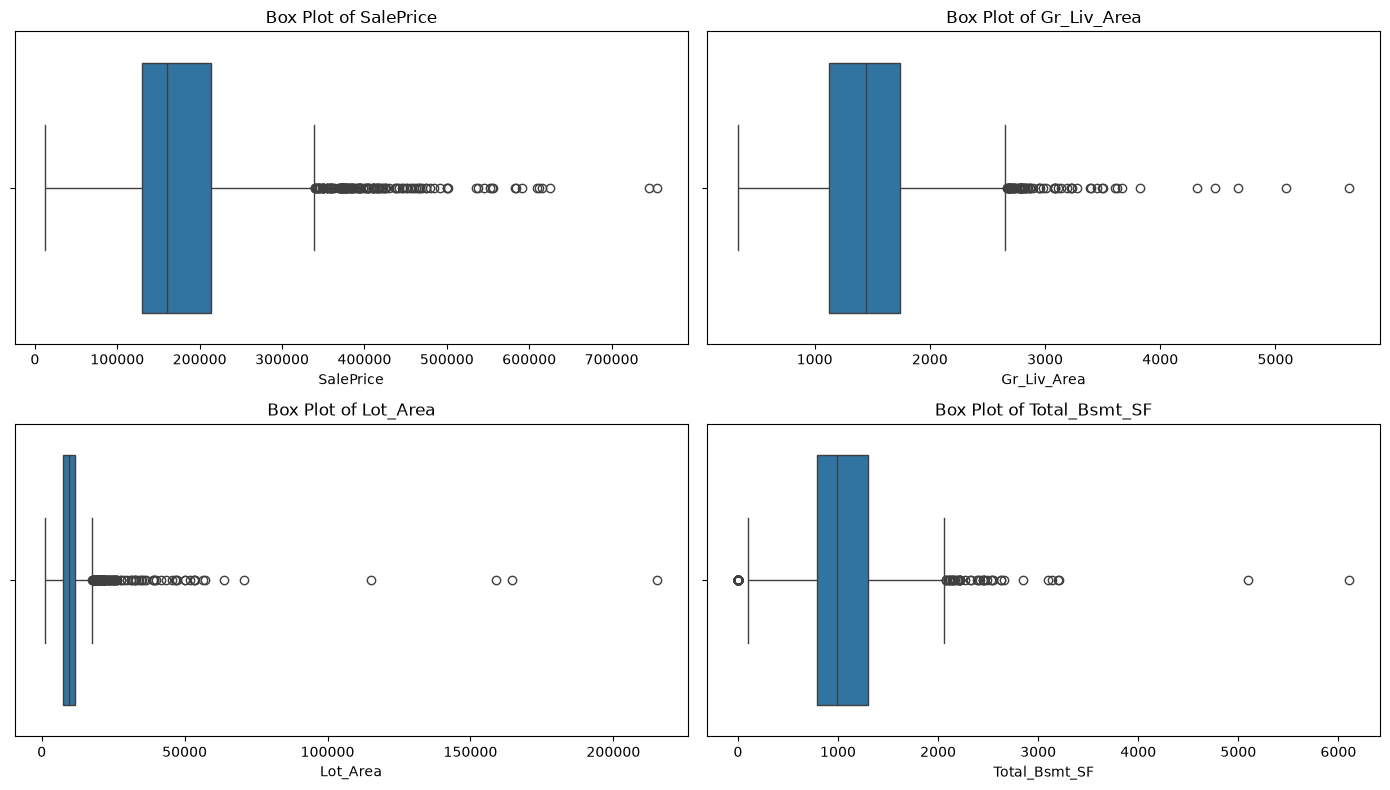

In [15]:
boxplot_columns = ["SalePrice", "Gr_Liv_Area", "Lot_Area", "Total_Bsmt_SF"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for axis, column in zip(axes, boxplot_columns):
    sns.boxplot(data=df, x=column, ax=axis)
    axis.set_title(f"Box Plot of {column}")

plt.tight_layout()
plt.show()

## 10. 범주형 변수 분포 확인

[Question 7]  
- 범주 수가 가장 많은 변수는 무엇인가?
- 특정 범주에 관측값이 지나치게 집중되어 있는가?
- 표본 수가 매우 적은 범주는 향후 인코딩과 모델링에 어떤 문제를 만들 수 있는가?


In [16]:
for column in categorical_columns:
    print(f"\n=== {column} ===")
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("Count")
        .assign(Ratio=lambda x: x["Count"] / len(df) * 100)
    )



=== Neighborhood ===


,Count,Ratio
Neighborhood,,
NAmes,443,15.12
CollgCr,267,9.11
OldTown,239,8.16
Edwards,194,6.62
Somerst,182,6.21
NridgHt,166,5.67
Gilbert,165,5.63
Sawyer,151,5.15
NWAmes,131,4.47



=== House_Style ===


,Count,Ratio
House_Style,,
1Story,1481,50.55
2Story,873,29.80
1.5Fin,314,10.72
SLvl,128,4.37
SFoyer,83,2.83
2.5Unf,24,0.82
1.5Unf,19,0.65
2.5Fin,8,0.27



=== Kitchen_Qual ===


,Count,Ratio
Kitchen_Qual,,
TA,1494,50.99
Gd,1160,39.59
Ex,205,7.00
Fa,70,2.39
Po,1,0.03



=== Exter_Qual ===


,Count,Ratio
Exter_Qual,,
TA,1799,61.40
Gd,989,33.75
Ex,107,3.65
Fa,35,1.19


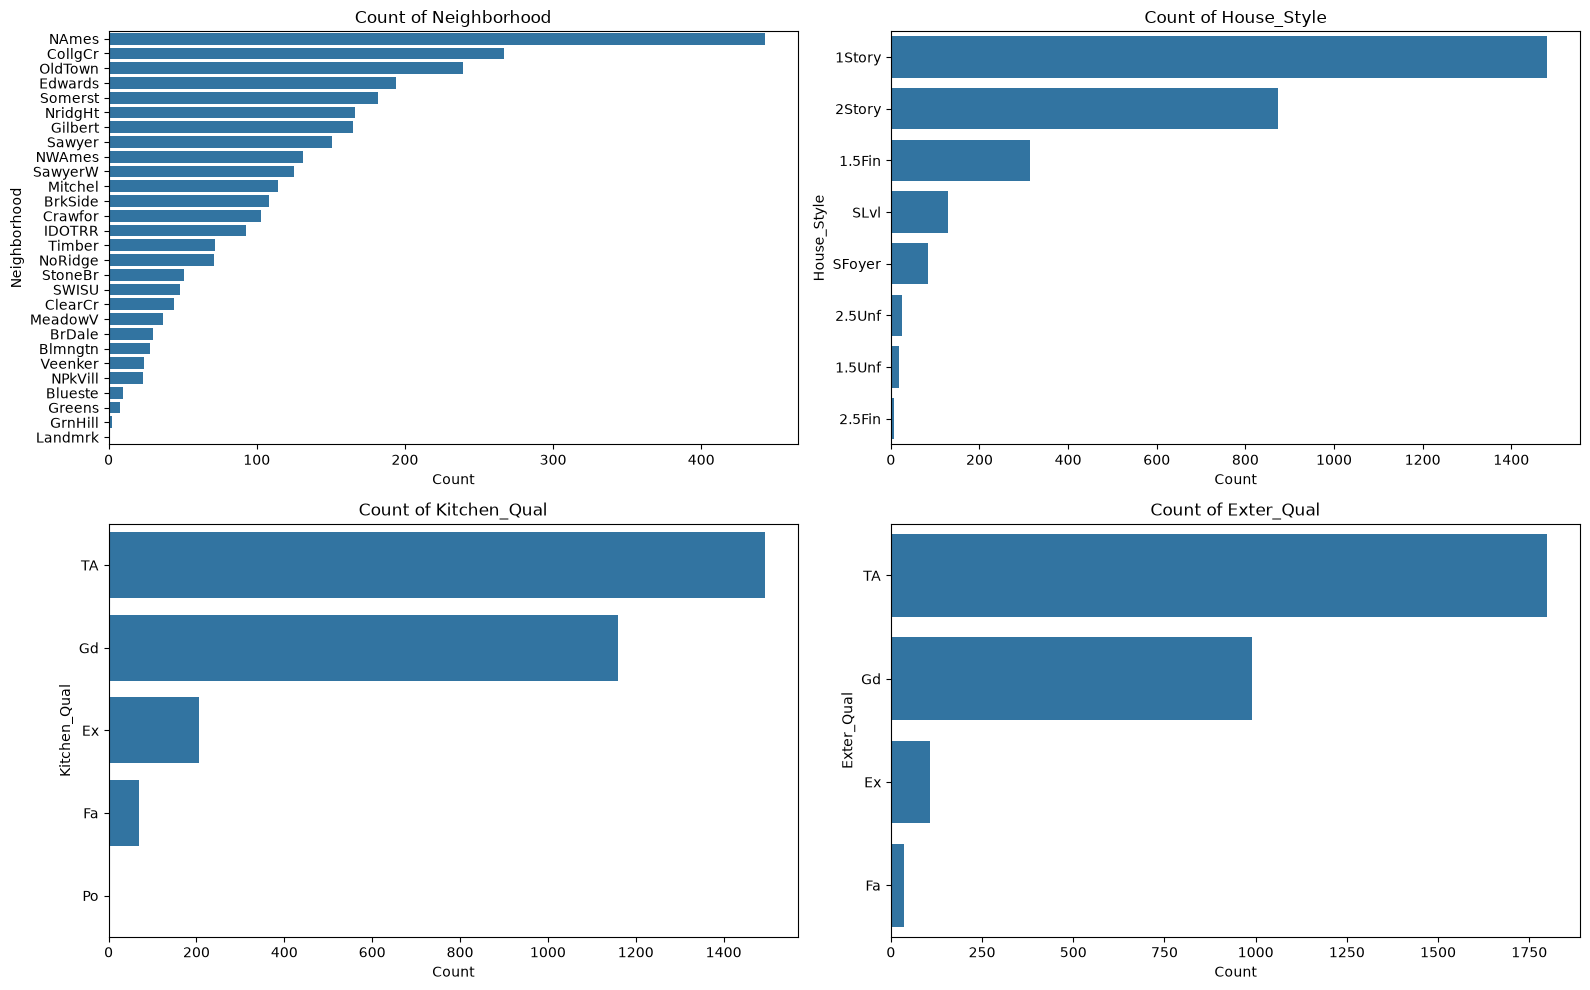

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for axis, column in zip(axes, categorical_columns):
    order = df[column].value_counts().index
    sns.countplot(data=df, y=column, order=order, ax=axis)
    axis.set_title(f"Count of {column}")
    axis.set_xlabel("Count")

plt.tight_layout()
plt.show()

## 11. 수치형 변수와 주택가격의 관계

[Question 8]  
- 주택가격과 가장 강한 양의 관계를 보이는 변수는 무엇인가?
- 품질 점수와 면적 중 어느 변수가 가격 차이를 더 분명하게 설명하는가?
- 상관계수가 낮아도 비선형 관계가 존재할 수 있는가?
- 상관관계만으로 인과관계를 주장할 수 있는가?


In [18]:
correlation = (
    df[numeric_columns]
    .corr(numeric_only=True)[target]
    .sort_values(ascending=False)
    .to_frame("Correlation_with_SalePrice")
)

display(correlation)

,Correlation_with_SalePrice
SalePrice,1.00
Overall_Qual,0.80
Gr_Liv_Area,0.71
Garage_Cars,0.65
Total_Bsmt_SF,0.63
Year_Built,0.56
Full_Bath,0.55
Garage_Yr_Blt,0.53
Lot_Area,0.27
Bedroom_AbvGr,0.14


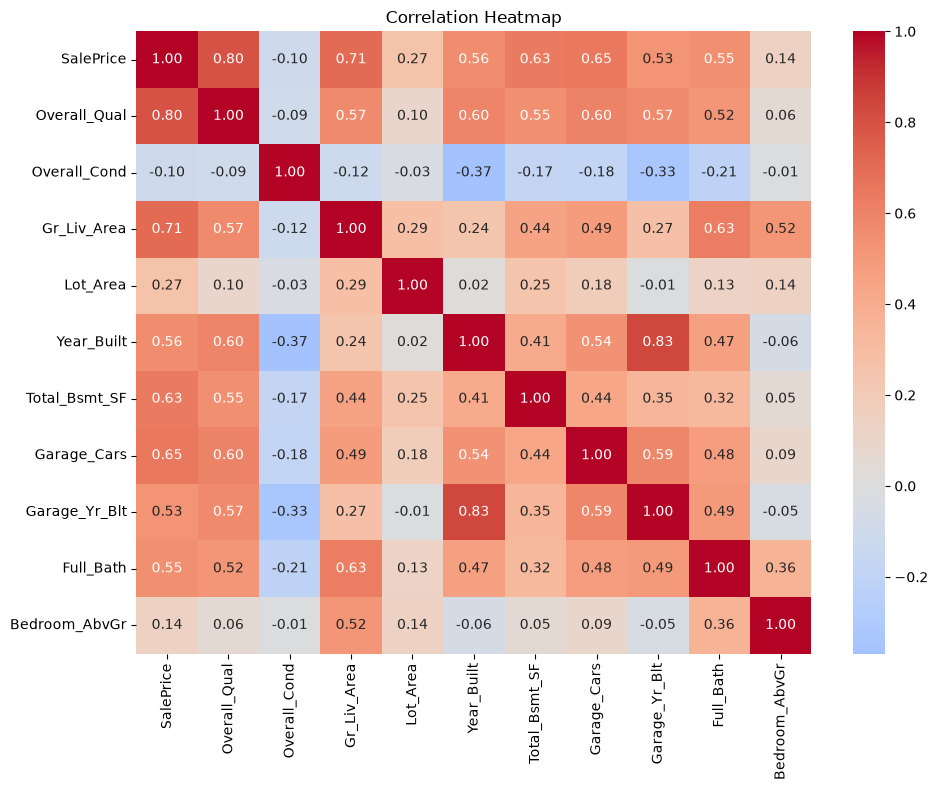

In [19]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    df[numeric_columns].corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

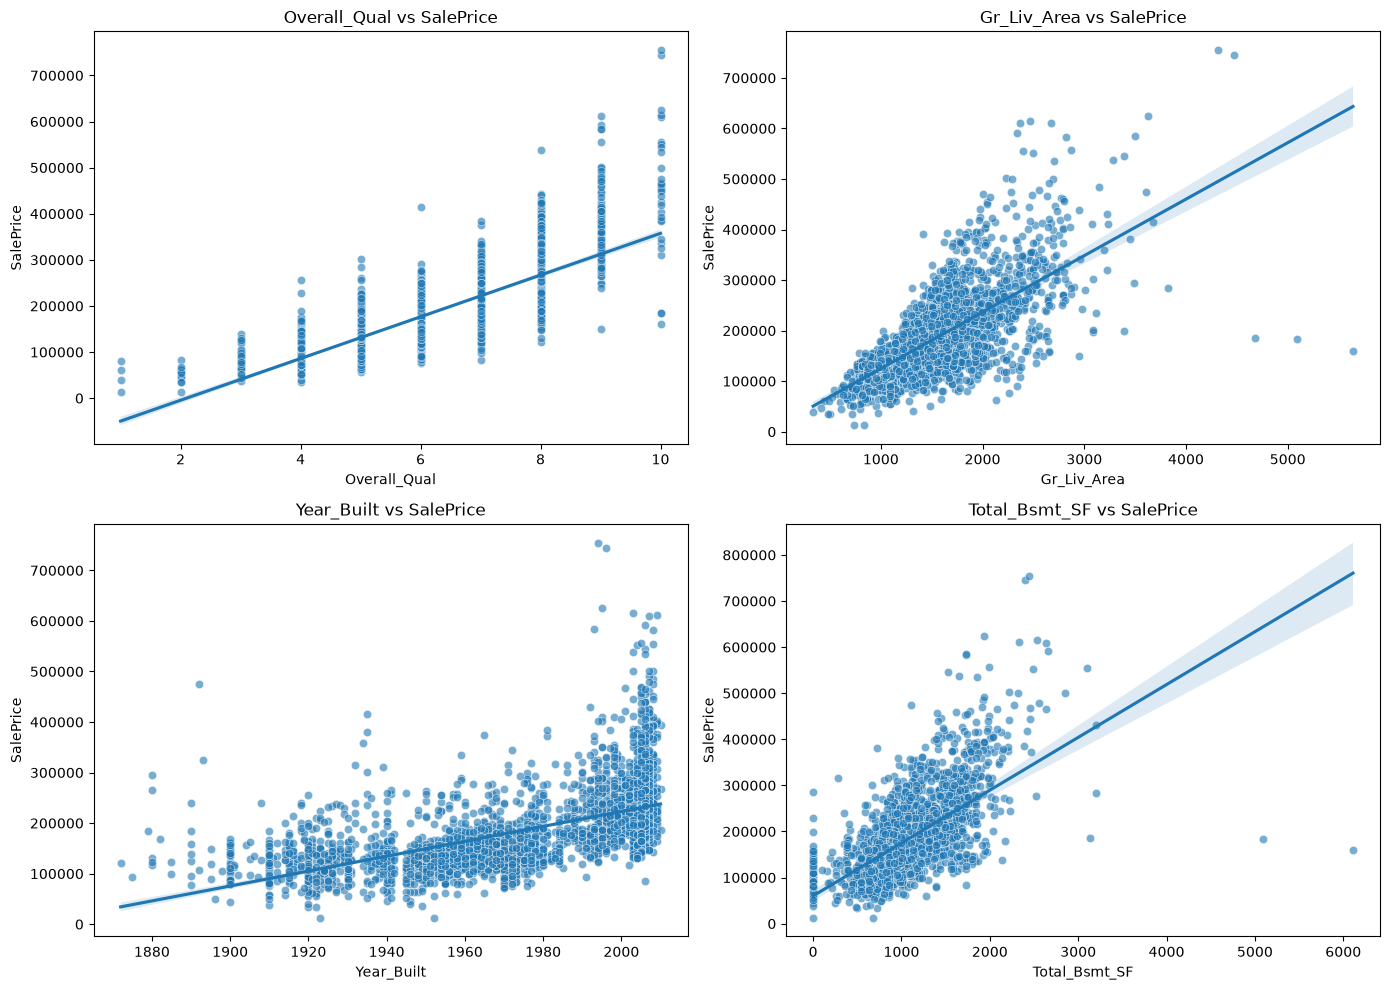

In [20]:
relationship_columns = [
    "Overall_Qual",
    "Gr_Liv_Area",
    "Year_Built",
    "Total_Bsmt_SF"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for axis, column in zip(axes, relationship_columns):
    sns.scatterplot(data=df, x=column, y=target, alpha=0.6, ax=axis)
    sns.regplot(data=df, x=column, y=target, scatter=False, ax=axis)
    axis.set_title(f"{column} vs SalePrice")

plt.tight_layout()
plt.show()

## 12. 범주형 변수와 주택가격의 관계

[Question 9]  
- 지역별 주택가격 중앙값에 차이가 있는가?
- 주방 품질과 외장 품질이 높아질수록 가격도 높아지는가?
- 범주별 표본 수가 다를 때 박스플롯을 어떻게 해석해야 하는가?
- 범주형 변수는 향후 회귀모델에 바로 입력할 수 있는가?


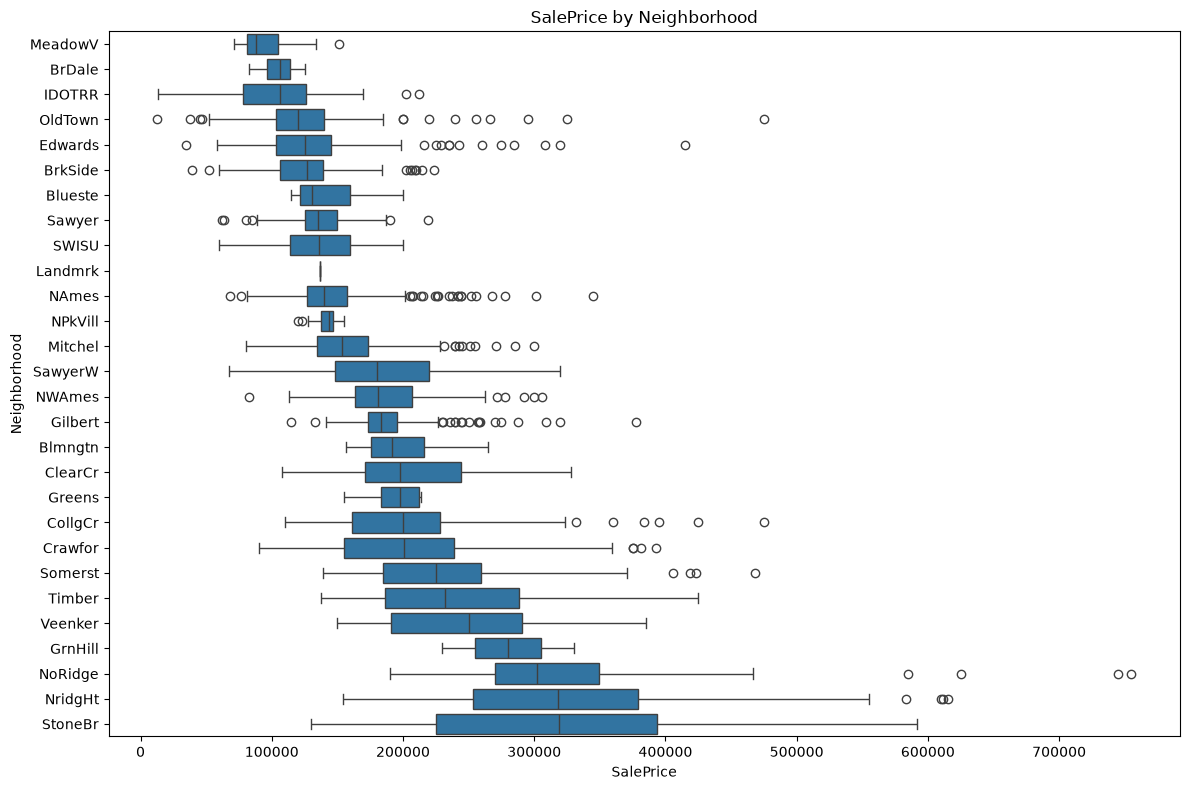

In [21]:
# Neighborhood별 주택가격 중앙값 순서
neighborhood_order = (
    df.groupby("Neighborhood", observed=False)[target]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(12, 8))
sns.boxplot(
    data=df,
    y="Neighborhood",
    x=target,
    order=neighborhood_order
)
plt.title("SalePrice by Neighborhood")
plt.tight_layout()
plt.show()

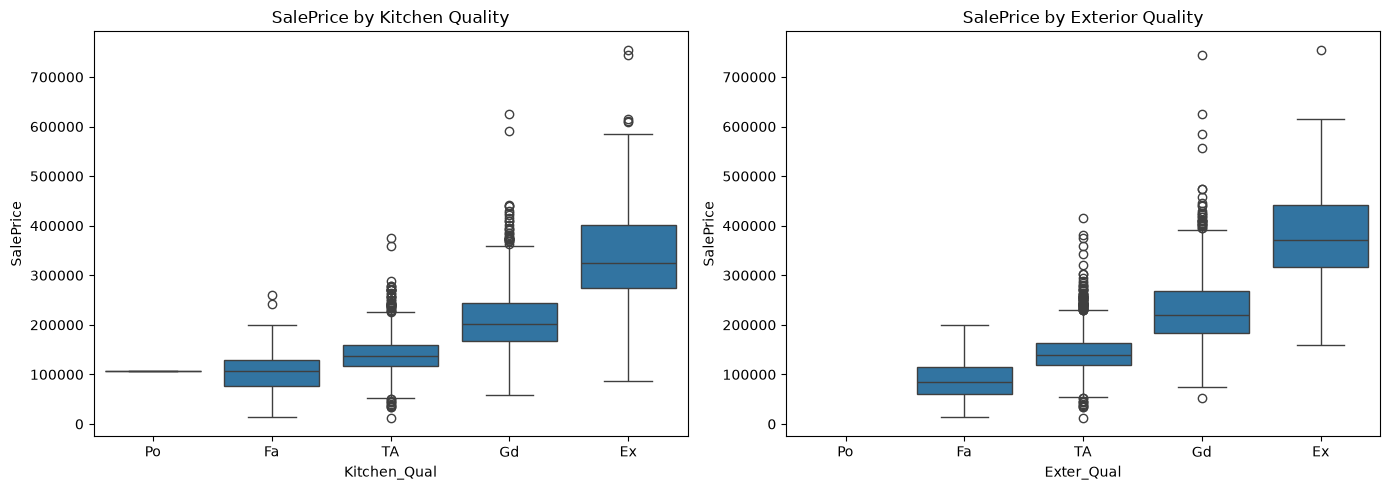

In [22]:
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Kitchen_Qual",
    y=target,
    order=quality_order,
    ax=axes[0]
)
axes[0].set_title("SalePrice by Kitchen Quality")

sns.boxplot(
    data=df,
    x="Exter_Qual",
    y=target,
    order=quality_order,
    ax=axes[1]
)
axes[1].set_title("SalePrice by Exterior Quality")

plt.tight_layout()
plt.show()

## 13. 주요 변수 교차 탐색

[Question 10]  
- 동일한 생활면적이라도 품질에 따라 가격 차이가 나타나는가?
- Overall_Qual은 면적과 가격의 관계를 어떻게 구분하는가?
- 단일 변수만 보는 것보다 두 변수를 함께 볼 때 새롭게 발견되는 패턴은 무엇인가?


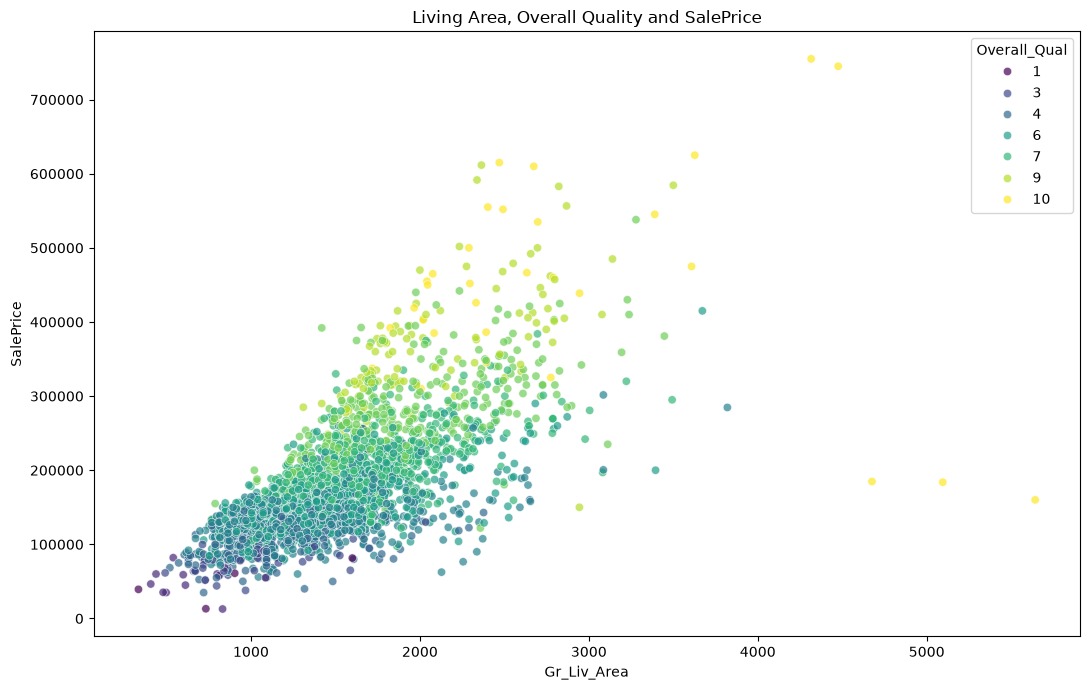

In [23]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df,
    x="Gr_Liv_Area",
    y=target,
    hue="Overall_Qual",
    palette="viridis",
    alpha=0.7
)
plt.title("Living Area, Overall Quality and SalePrice")
plt.tight_layout()
plt.show()

## 14. EDA Findings 작성

[Report]  
아래 질문에 대한 답을 관찰 근거와 함께 작성하세요.

1. 데이터 구조에서 확인한 특징은 무엇인가?
2. 결측치가 있는 변수와 결측의 가능한 의미는 무엇인가?
3. Target 분포의 특징과 향후 고려할 변환은 무엇인가?
4. 이상치 후보가 확인된 변수와 처리 전 확인할 사항은 무엇인가?
5. 주택가격과 관계가 강해 보이는 수치형 변수는 무엇인가?
6. 가격 차이가 뚜렷하게 나타나는 범주형 변수는 무엇인가?
7. 향후 전처리 단계에서 수행해야 할 작업은 무엇인가?

[Example Format]  
- Finding:
- Evidence:
- Possible Action:
